# Markov Chains and Mario Jazz

The first part of this notebook demonstrates a very simple way to produce a Markov Chain from some source text, based on constructing character-level and word-level n-grams, and then use this to generate some new text. The first part concludes with a demonstration of combining different source texts to produce novel outputs.

The second part of this notebook explores the use of a Markov chain to produce simple tunes by using simple tokens to represent notes. **Note:** While you can complete the first part of this notebook in Google Colad, to complete the second part of this notebook you will need to download and run it locally, e.g., using Jupyter Lab, so that you can hear the audio output (which doesn't yet work in Google Colab).

## Part 1: Markov Chains

Using Markov models/chains is one of the oldest methods for generating text.

### What is a Markov Chain?

A Markov Chain is a stochastic process that is "memory-less". That is, the probability of *future* states are not dependent upon the states that preceded the *present* state.

The general property of a Markov Chain is:

$ P(X_{n+1} = j \mid X_0 = i_0, X_1 = i_1, \dots X_{n-1} = i_{n-1}, X_n = i) = P(X_{n+1} = j \mid X_n = i) $

See lecture 7a on Brightspace for more information on Markov Chains.

### Generating Text with a Character-based Markov Chain

For the initial demonstration of building a Markov Chain we will use the following excerpt of text from Alice in Wonderland.

<font size="4" color="#1E90FF"><b>Please note that new code blocks are written under the blue headings </b></font>


In [7]:
input_text = "Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, `and what is the use of a book,' thought Alice `without pictures or conversation?' So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a White Rabbit with pink eyes ran close by her. There was nothing so very remarkable in that; nor did Alice think it so very much out of the way to hear the Rabbit say to itself, `Oh dear! Oh dear! I shall be late!' (when she thought it over afterwards, it occurred to her that she ought to have wondered at this, but at the time it all seemed quite natural); but when the Rabbit actually took a watch out of its waistcoat-pocket, and looked at it, and then hurried on, Alice started to her feet, for it flashed across her mind that she had never before seen a rabbit with either a waistcoat-pocket, or a watch to take out of it, and burning with curiosity, she ran across the field after it, and fortunately was just in time to see it pop down a large rabbit-hole under the hedge."

<font size="4" color="#1E90FF"><b>New Example</b></font>


In [8]:
LIACS_text = "The LIACS staff is invited to a conference today - titled 'LIACS heroes' - in the general meeting room"

We can display an extract of the input text and format it for the screen using `textwrap`:

In [9]:
import textwrap
print(textwrap.fill(input_text, 80))

Alice was beginning to get very tired of sitting by her sister on the bank, and
of having nothing to do: once or twice she had peeped into the book her sister
was reading, but it had no pictures or conversations in it, `and what is the use
of a book,' thought Alice `without pictures or conversation?' So she was
considering in her own mind (as well as she could, for the hot day made her feel
very sleepy and stupid), whether the pleasure of making a daisy-chain would be
worth the trouble of getting up and picking the daisies, when suddenly a White
Rabbit with pink eyes ran close by her. There was nothing so very remarkable in
that; nor did Alice think it so very much out of the way to hear the Rabbit say
to itself, `Oh dear! Oh dear! I shall be late!' (when she thought it over
afterwards, it occurred to her that she ought to have wondered at this, but at
the time it all seemed quite natural); but when the Rabbit actually took a watch
out of its waistcoat-pocket, and looked at it, and the

### Step 1: Create a Dictionary to Capture Transition Probabilities

To implement a Markov chain, we are going to create a **dictionary of n-grams**. To start we will create n-grams based on characters, not words, from the input text. For the moment, we will construct a Markov chain using n-grams of length 3, or trigrams. But the order of the n-grams is a parameter that can be tuned later to get better (or more interesting) generated texts.

The first step is to divide the text into n-grams. For this dictionary, the first part of the n-grams will be the keys and each instance of the last character that completes an n-gram will be added to an array as the value for the key.

This means that if an n-gram appears twice in the input text, then the array for the n-gram in the disction will contain the last character of the n-gram twice. This captures the frequency with which an n-gram appears in the input text, but perhaps not in the most elegant, or space-efficient, way.

To build the Markkov chain we'll define a function `markov()` that takes the input text and the n-gram order. Note in the implementation that the length of the keys used in the dictionary is one less than the n-gram order, with a minimum length of 1, so this does not support unigrams (order=1), which makes sense as the smallest n-gram to capture transitions would be a bigram (order=2) model. The function will default to building a bigram model if a unigram is requested.

In [10]:
def markov(seq, order):
  # the length of the keys is one less than the n-gram order
  keylen = order-1 if order > 2 else 1;
  markov_dict = {}
  seq = list(seq[:]) + [None]
  for i in range(len(seq) - keylen):
      key = tuple(seq[i:i+keylen])
      if key not in markov_dict:
          markov_dict[key] = []
      markov_dict[key].append(seq[i+keylen])
  return markov_dict

Naturally, we can inspect the output of the dictionary:

In [11]:
markov_dict_chars = markov(input_text, 3)
print(textwrap.fill(str(markov_dict_chars)[:960], 80))

{('A', 'l'): ['i', 'i', 'i', 'i'], ('l', 'i'): ['c', 'c', 'c', 'c'], ('i', 'c'):
['e', 'e', 't', 'e', 't', 'k', 'e', 'e'], ('c', 'e'): [' ', ' ', ' ', ' ', ' ',
' '], ('e', ' '): ['w', 'b', 'o', 's', 'h', 'b', 'u', 'o', '`', 'w', 'c', 'h',
'h', 'p', 'o', 'w', 't', 'o', 'd', 'R', 'b', 'w', 'i', 't', 'w', 'R', 'l', 't',
'o', 'w', 't', 'i', 'n', 'R', 's', 'h', 's', 'o', 'r', 'f', 't', 'i', 'r', 'u',
'h'], (' ', 'w'): ['a', 'a', 'h', 'a', 'e', 'h', 'o', 'o', 'h', 'i', 'a', 'a',
'o', 'h', 'a', 'a', 'i', 'a', 'a', 'i', 'a'], ('w', 'a'): ['s', 's', 's', 's',
'y', 'r', 't', 'i', 'i', 't', 's'], ('a', 's'): [' ', ' ', ' ', ' ', ' ', 'u', '
', 'h', ' '], ('s', ' '): ['b', 'r', 'o', 'i', 't', 'o', 'c', 'w', 's', 'r',
'n', 'w', 'h', 't', 'j'], (' ', 'b'): ['e', 'y', 'a', 'o', 'u', 'o', 'e', 'y',
'e', 'u', 'u', 'e', 'u'], ('b', 'e'): ['g', ' ', ' ', 'f'], ('e', 'g'): ['i'],
('g', 'i'): ['n'], ('i', 'n'): ['n', 'g', 'g', 'g', 'g', 't', 'g', ' ', 'g', '
', 'd',


<font size="4" color="#1E90FF"><b>Inspecting markov chain for original text with order = 3 without character limitation</b></font>

In [12]:
markov_dict_chars = markov(input_text, 3)
print(textwrap.fill(str(markov_dict_chars), 80))

{('A', 'l'): ['i', 'i', 'i', 'i'], ('l', 'i'): ['c', 'c', 'c', 'c'], ('i', 'c'):
['e', 'e', 't', 'e', 't', 'k', 'e', 'e'], ('c', 'e'): [' ', ' ', ' ', ' ', ' ',
' '], ('e', ' '): ['w', 'b', 'o', 's', 'h', 'b', 'u', 'o', '`', 'w', 'c', 'h',
'h', 'p', 'o', 'w', 't', 'o', 'd', 'R', 'b', 'w', 'i', 't', 'w', 'R', 'l', 't',
'o', 'w', 't', 'i', 'n', 'R', 's', 'h', 's', 'o', 'r', 'f', 't', 'i', 'r', 'u',
'h'], (' ', 'w'): ['a', 'a', 'h', 'a', 'e', 'h', 'o', 'o', 'h', 'i', 'a', 'a',
'o', 'h', 'a', 'a', 'i', 'a', 'a', 'i', 'a'], ('w', 'a'): ['s', 's', 's', 's',
'y', 'r', 't', 'i', 'i', 't', 's'], ('a', 's'): [' ', ' ', ' ', ' ', ' ', 'u', '
', 'h', ' '], ('s', ' '): ['b', 'r', 'o', 'i', 't', 'o', 'c', 'w', 's', 'r',
'n', 'w', 'h', 't', 'j'], (' ', 'b'): ['e', 'y', 'a', 'o', 'u', 'o', 'e', 'y',
'e', 'u', 'u', 'e', 'u'], ('b', 'e'): ['g', ' ', ' ', 'f'], ('e', 'g'): ['i'],
('g', 'i'): ['n'], ('i', 'n'): ['n', 'g', 'g', 'g', 'g', 't', 'g', ' ', 'g', '
', 'd', 'g', ' ', 'g', 'g', 'k', 'g', ' ', 'k',

<font size="4" color="#1E90FF"><b>Inspecting markov chain for LIACS text</b></font>


In [13]:
markov_dict_chars_LIACS = markov(LIACS_text, 3)
print(textwrap.fill(str(markov_dict_chars_LIACS)[:960], 80))

{('T', 'h'): ['e'], ('h', 'e'): [' ', 'r', ' '], ('e', ' '): ['L', 't', 'g'], ('
', 'L'): ['I'], ('L', 'I'): ['A', 'A'], ('I', 'A'): ['C', 'C'], ('A', 'C'):
['S', 'S'], ('C', 'S'): [' ', ' '], ('S', ' '): ['s', 'h'], (' ', 's'): ['t'],
('s', 't'): ['a'], ('t', 'a'): ['f'], ('a', 'f'): ['f'], ('f', 'f'): [' '],
('f', ' '): ['i'], (' ', 'i'): ['s', 'n', 'n'], ('i', 's'): [' '], ('s', ' '):
['i'], ('i', 'n'): ['v', ' ', 'g'], ('n', 'v'): ['i'], ('v', 'i'): ['t'], ('i',
't'): ['e', 'l'], ('t', 'e'): ['d'], ('e', 'd'): [' ', ' '], ('d', ' '): ['t',
"'"], (' ', 't'): ['o', 'o', 'i', 'h'], ('t', 'o'): [' ', 'd'], ('o', ' '):
['a'], (' ', 'a'): [' '], ('a', ' '): ['c'], (' ', 'c'): ['o'], ('c', 'o'):
['n'], ('o', 'n'): ['f'], ('n', 'f'): ['e'], ('f', 'e'): ['r'], ('e', 'r'):
['e', 'o', 'a'], ('r', 'e'): ['n'], ('e', 'n'): ['c', 'e'], ('n', 'c'): ['e'],
('c', 'e'): [' '], ('o', 'd'): ['a'], ('d', 'a'): ['y'], ('a', 'y'): [' '],
('y', ' '): ['-'], (' ', '-


Plotting a histogram of the lengths of the arrays associated with each key can provide some insight into the potential for the model to produce novel texts; keys with more than one possible ending provide more possible transitions from each state and hence more branching options:

[4, 4, 8, 6, 45, 21, 11, 9, 15, 13, 4, 1, 1, 22, 1, 2, 11, 10, 37, 11, 14, 2, 4, 6, 30, 4, 9, 26, 4, 13, 7, 1, 10, 10, 25, 22, 8, 8, 21, 6, 27, 2, 2, 17, 39, 23, 8, 7, 9, 9, 15, 30, 1, 11, 3, 2, 17, 25, 12, 11, 2, 1, 6, 4, 3, 5, 8, 2, 1, 1, 1, 10, 1, 5, 9, 5, 7, 2, 7, 2, 19, 1, 2, 4, 4, 4, 6, 5, 2, 1, 4, 7, 5, 3, 6, 8, 4, 6, 6, 2, 2, 3, 16, 3, 2, 7, 3, 1, 5, 3, 2, 6, 8, 1, 3, 5, 10, 3, 3, 3, 3, 1, 1, 1, 1, 1, 3, 7, 3, 2, 2, 5, 2, 2, 1, 1, 5, 4, 4, 2, 3, 1, 7, 4, 3, 3, 3, 2, 1, 5, 1, 2, 1, 1, 1, 2, 2, 2, 5, 1, 1, 1, 4, 3, 3, 9, 1, 3, 1, 2, 2, 3, 3, 3, 6, 1, 1, 1, 3, 1, 1, 3, 3, 6, 5, 5, 2, 1, 1, 5, 1, 2, 4, 1, 1, 1, 1, 2, 2, 7, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 1, 4, 3, 3, 1, 1, 1, 1, 2, 2, 1, 1, 1, 3, 1, 2, 2, 2, 3, 1, 1, 1, 2, 1, 1, 3, 1, 4, 2, 3, 2, 3, 4, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1]


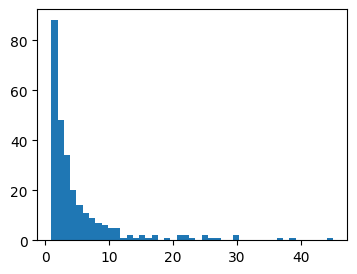

In [14]:
import matplotlib.pyplot as plt
def plot_histogram(markov_dict):
    h = [len(v) for v in markov_dict.values()]
    print(h)
    fig, ax = plt.subplots(figsize=(4,3))
    ax.hist(h, bins=max(h))
    ax.locator_params(axis='y', integer=True)
    ax.locator_params(axis='x', integer=True)

plot_histogram(markov_dict_chars)

<font size="4" color="#1E90FF"><b>Inspecting markov chain histogram for LIACS text</b></font>

[1, 3, 3, 1, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 2, 1, 2, 2, 4, 2, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


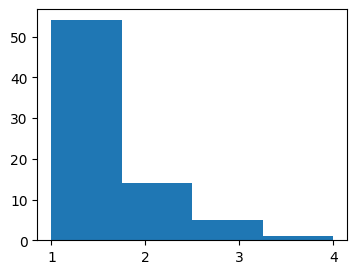

In [15]:
plot_histogram(markov_dict_chars_LIACS)

<font size="4" color="#1E90FF"><b>Getting transition history along with histogram for Alice text</b></font>

Transition history:
transition 1 : 88 sequences
transition 2 : 48 sequences
transition 3 : 34 sequences
transition 4 : 20 sequences
transition 5 : 14 sequences
transition 6 : 11 sequences
transition 7 : 9 sequences
transition 8 : 7 sequences
transition 9 : 6 sequences
transition 10 : 5 sequences
transition 11 : 5 sequences
transition 12 : 1 sequences
transition 13 : 2 sequences
transition 14 : 1 sequences
transition 15 : 2 sequences
transition 16 : 1 sequences
transition 17 : 2 sequences
transition 19 : 1 sequences
transition 21 : 2 sequences
transition 22 : 2 sequences
transition 23 : 1 sequences
transition 25 : 2 sequences
transition 26 : 1 sequences
transition 27 : 1 sequences
transition 30 : 2 sequences
transition 37 : 1 sequences
transition 39 : 1 sequences
transition 45 : 1 sequences


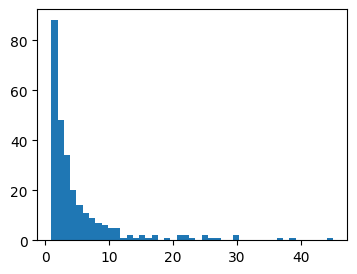

In [16]:
#H is just the list of the lengths of the value arrays, but i want to show that 2 transitions are available for k number of keys.
#strategy :1. print out count of transitions against character sequences.
#2. print out transition number and the number of textual sequences associated that transition number like : "transition 3 : 8 sequences"

import matplotlib.pyplot as plt
from collections import Counter

def plot_histogram_upd(markov_dict):
    h = [len(v) for v in markov_dict.values()]
    transition_counts = Counter(h)

    print("Transition history:")
    for transition_num, count in sorted(transition_counts.items()):
        print(f"transition {transition_num} : {count} sequences")

    fig, ax = plt.subplots(figsize=(4,3))
    ax.hist(h, bins=max(h))
    ax.locator_params(axis='y', integer=True)
    ax.locator_params(axis='x', integer=True)

plot_histogram_upd(markov_dict_chars)


<font size="4" color="#1E90FF"><b>Getting transition history along with histogram for LIACS text</b></font>

Transition history:
transition 1 : 54 sequences
transition 2 : 14 sequences
transition 3 : 5 sequences
transition 4 : 1 sequences


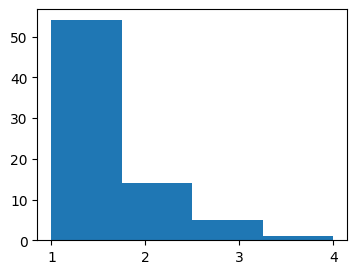

In [17]:
plot_histogram_upd(markov_dict_chars_LIACS)

#### Step 2: Generate Text

After defining the states of the Markov chain the n-gram model can be used generate text. By default the starting point for generation is a random n-gram in the text of the length of the keys used in the model, which is one less than the n-gram order given to `markov()`. This is asigned to `key` which is appended to `output`. Then `random.choice()` picks the next character from the array associated with `key` to complete the n-gram, and this character is appended to `output`. The value of `key` is then updated from the last characters in `output`. The default length of the generated text is arbitrarily set to 500 but this can be changed by supplying a value for `length`.

In [18]:
import random
def generate(markov_dict, length=500, start=None):
    keys = list(markov_dict.keys())
    order = len(keys[0])
    if start == None or len(start) != order or not (tuple(start) in keys):
      key = random.choice(keys)
    else:
      key = tuple(start)
    output = list(key)
    for i in range(length-order):
        next = random.choice(markov_dict[key])
        if next == None:
          break;
        else:
          output.append(next)
        key = tuple(output[-order:])
    return output

To use `generate()` we provide the dictionary constructed by `markov()` and combine the output together using `''.join()` to produce a string.

In [19]:
markov_dict_chars = markov(input_text, 3)
output_text = ''.join(generate(markov_dict_chars))
print(textwrap.fill(output_text, 80))

clook,' So day sher. The dery watund as sisit of he it pice ink it haver itseld
nothing sisisy-ch to ver thered ortedgethould, of it th der the tards, she he
itting wit, shet, acturninnind ther and she se of it, an then much to had a was
wit and and large.



<font size="4" color="#1E90FF"><b>Generating text from LIACS text markov chain with order = 3</b></font>

In [20]:
markov_dict_chars_LIACS = markov(LIACS_text, 3)
LIACS_output_text = ''.join(generate(markov_dict_chars_LIACS))
print(textwrap.fill(LIACS_output_text, 80))

nce gence generence LIACS staff in titled 'LIACS he the gence LIACS staff is is
ing roes' - is invited tin the gence LIACS heroom


The output doesn't look great, some of the words are correct but a lot of them are non-sense. Let's try with a larger n-gram order of 4:

In [21]:
markov_dict_chars = markov(input_text, 4)
output_text = ''.join(generate(markov_dict_chars))
print(textwrap.fill(output_text, 80))

rkable undering in the ther feel very sleepy and forth eith took her the
undering so very much out occuriositting a large rabbit-hole of get
versationsider the Rabbit occurred that; nor did Alice she hot day to her feet,
fortunately to her that so ver sister feel very remarkable ought Alice was cons
in time in hurried in here started at the daister mind look,' the rabbit of it
at to take out in would at say took a was be late!' (whethe hed of had picking a
rabbit she by hear! Oh dear ther mind p


<font size="4" color="#1E90FF"><b>Inspecting markov chain for original text with order = 4 without character limitation</b></font>

In [22]:
markov_dict_chars = markov(input_text, 4)
print(textwrap.fill(str(markov_dict_chars), 80))

{('A', 'l', 'i'): ['c', 'c', 'c', 'c'], ('l', 'i', 'c'): ['e', 'e', 'e', 'e'],
('i', 'c', 'e'): [' ', ' ', ' ', ' ', ' '], ('c', 'e', ' '): ['w', 'o', 's',
'`', 't', 's'], ('e', ' ', 'w'): ['a', 'a', 'o', 'a', 'a', 'o'], (' ', 'w',
'a'): ['s', 's', 's', 's', 'y', 't', 'i', 'i', 't', 's'], ('w', 'a', 's'): [' ',
' ', ' ', ' ', ' '], ('a', 's', ' '): ['b', 'r', 'c', 'w', 's', 'n', 'j'], ('s',
' ', 'b'): ['e'], (' ', 'b', 'e'): ['g', ' ', ' ', 'f'], ('b', 'e', 'g'): ['i'],
('e', 'g', 'i'): ['n'], ('g', 'i', 'n'): ['n'], ('i', 'n', 'n'): ['i'], ('n',
'n', 'i'): ['n'], ('n', 'i', 'n'): ['g', 'g'], ('i', 'n', 'g'): [' ', ' ', ' ',
' ', ',', ' ', ' ', ' ', ' ', ' ', ' '], ('n', 'g', ' '): ['t', 'b', 'n', 't',
'i', 'a', 'u', 't', 's', 'w'], ('g', ' ', 't'): ['o', 'o', 'h'], (' ', 't',
'o'): [' ', ' ', ' ', ' ', ' ', ' ', 'o', ' ', ' ', ' '], ('t', 'o', ' '): ['g',
'd', 't', 'h', 'i', 'h', 'h', 'h', 't', 's'], ('o', ' ', 'g'): ['e'], (' ', 'g',
'e'): ['t', 't'], ('g', 'e', 't'): [' ', 't'], ('e


<font size="4" color="#1E90FF"><b>Generating text from LIACS text markov chain with order = 4</b></font>

In [23]:
markov_dict_chars_LIACS = markov(LIACS_text, 4)
LIACS_output_text = ''.join(generate(markov_dict_chars_LIACS))
print(textwrap.fill(LIACS_output_text, 80))

e general meeting room


That's much better! The words are generally well-formed and while the text might not make much sense it at least mostly looks like natural language. Notice that sometimes the `generate()` function doesn't produce the requested number of characters. This happens when the Markov chain produces the final n-gram in the input_text 'dge.' because there are no characters in the input text that follow 'ge.', which would the the key for the next n-gram and so the function terminates.

#### Providing some starting text

The `generate()` function allows some starting text to be provided as a parameter. The provided text must be at least as long as the keys in the dictionary, so one less than the order of the n-grams used to construct the Markov chain, and the starting text must appear in the input text used to construct the Markov chain. Otherwise the starting text will be ignored and the function will return text generated using a random n-gram from the text.

In [24]:
markov_dict = markov(input_text, 4)
output_text = ''.join(generate(markov_dict, 1000, "Whi"))
print(textwrap.fill(output_text, 80))

White Rabbit of itself, `Oh dear! I shedge.



<font size="4" color="#1E90FF"><b>Generating text from Alice text markov chain with order = 4 with nonsensical input sequence</b></font>

In [25]:
markov_dict = markov(input_text, 4)
output_text = ''.join(generate(markov_dict, 1000, "Alo"))
print(textwrap.fill(output_text, 80))

e pleasures rabbit having withe have way to get ver sistcoat-pocket, or itself,
`and burning so versation?' So seemed at she could but of sity, she Rabbit with
eithought Alice `without with curred of getting to her own a day time it all
seemed after mind this, but is the undering in wondered at took a waisy-chain
tired of it, or twice `withe wortunature of it, `and look a way to take or it
having by hed of it all see into getting in think its was be wondering a was
well be large rabbit she the of it all befor could be wortunate!' (when suddenly
time it overy making to shally to her feet, `and to she Rabbit of the had nevery
made her be was just itself, `and but occurred of getting a was just it withe
tired on, Alice out at the rabbit of it so very much out what ther the was just
in wonder mind of that to her before started quite natures rabbit across the to
take or convery making to had nothink it, and what thout pink eyes ran a was
cons in it, or did Alice of had nothing, but pink it,


<font size="4" color="#1E90FF"><b>Generating text from LIACS text markov chain with order = 4 with sensical input sequence</b></font>

In [26]:
markov_dict_LIACS = markov(LIACS_text, 4)
LIACS_output_text = ''.join(generate(markov_dict_LIACS, 1000, "LIA"))
print(textwrap.fill(LIACS_output_text, 80))

LIACS heroes' - invited 'LIACS heroes' - titled 'LIACS heroes' - invited today -
in the LIACS heroes' - titled to a conference to a conference today - in the
LIACS staff is in the general meeting room



<font size="4" color="#1E90FF"><b>Generating text from LIACS text markov chain with order = 4 with nonsensical input sequence</b></font>

In [27]:
markov_dict_LIACS = markov(LIACS_text, 4)
LIACS_output_text = ''.join(generate(markov_dict_LIACS, 1000, "LIP"))
print(textwrap.fill(LIACS_output_text, 80))

- invited to a conference to a conference to a conference to a conference today
- titled to a conference to a conference today - titled today - invited today -
invited 'LIACS staff is invited today - titled today - titled to a conference to
a conference to a conference today - titled 'LIACS heroes' - invited 'LIACS
staff is invited to a conference to a conference to a conference today - titled
to a conference today - in the LIACS heroes' - titled to a conference today - in
the general meeting room


### Word-based generation

The `markov()` and `generate()` functions are not limited to character-based construction and generation. We can provide the `markov()` function with any sequence and it will construct a Markov chain with it. Likewise, the `generate()` function will work with any dictionary using sequences as keys.

The only change needed to start working with words is to process the input text first to split it into words and then join the words together with spaces afterwards. The following is a bare-bones version of this, it uses split to split the input text based on spaces only and joins the sequence of words produced with spaces.

In [28]:
input_words = input_text.split()
markov_dict_words = markov(input_words, 4)
output_words = ' '.join(generate(markov_dict_words, 100))
print(textwrap.fill(output_words, 80))

she had never before seen a rabbit with either a waistcoat-pocket, or a watch to
take out of it, and burning with curiosity, she ran across the field after it,
and fortunately was just in time to see it pop down a large rabbit-hole under
the hedge.


In [29]:
print(markov_dict_words)

{('Alice', 'was', 'beginning'): ['to'], ('was', 'beginning', 'to'): ['get'], ('beginning', 'to', 'get'): ['very'], ('to', 'get', 'very'): ['tired'], ('get', 'very', 'tired'): ['of'], ('very', 'tired', 'of'): ['sitting'], ('tired', 'of', 'sitting'): ['by'], ('of', 'sitting', 'by'): ['her'], ('sitting', 'by', 'her'): ['sister'], ('by', 'her', 'sister'): ['on'], ('her', 'sister', 'on'): ['the'], ('sister', 'on', 'the'): ['bank,'], ('on', 'the', 'bank,'): ['and'], ('the', 'bank,', 'and'): ['of'], ('bank,', 'and', 'of'): ['having'], ('and', 'of', 'having'): ['nothing'], ('of', 'having', 'nothing'): ['to'], ('having', 'nothing', 'to'): ['do:'], ('nothing', 'to', 'do:'): ['once'], ('to', 'do:', 'once'): ['or'], ('do:', 'once', 'or'): ['twice'], ('once', 'or', 'twice'): ['she'], ('or', 'twice', 'she'): ['had'], ('twice', 'she', 'had'): ['peeped'], ('she', 'had', 'peeped'): ['into'], ('had', 'peeped', 'into'): ['the'], ('peeped', 'into', 'the'): ['book'], ('into', 'the', 'book'): ['her'], ('the

If we want to supply some starting text, we just need to process it the same way as the input text:

In [30]:
output_words = ' '.join(generate(markov_dict_words, 100, "Alice was beginning".split()))
print(textwrap.fill(output_words, 80))

Alice was beginning to get very tired of sitting by her sister on the bank, and
of having nothing to do: once or twice she had peeped into the book her sister
was reading, but it had no pictures or conversations in it, `and what is the use
of a book,' thought Alice `without pictures or conversation?' So she was
considering in her own mind (as well as she could, for the hot day made her feel
very sleepy and stupid), whether the pleasure of making a daisy-chain would be
worth the trouble of getting up and picking the daisies,



<font size="4" color="#1E90FF"><b>Word based Generation for LIACS text</b></font>

In [31]:
input_words_LIACS = LIACS_text.split()
markov_dict_words_LIACS = markov(input_words_LIACS, 4)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100))
print(textwrap.fill(LIACS_output_words, 80))

LIACS staff is invited to a conference today - titled 'LIACS heroes' - in the
general meeting room



<font size="4" color="#1E90FF"><b>Word based Generation for LIACS text with sensical input sequence</b></font>

In [32]:
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100, "staff is invited".split()))
print(textwrap.fill(LIACS_output_words, 80))

staff is invited to a conference today - titled 'LIACS heroes' - in the general
meeting room


Now we can see that there is a problem with our word-based generation with this short input text, given the same starting text it produces the same output text. We can understand why if we look at the histogram of the value lengths in the dictionary, where we can see that there is only one possible ending for each n-gram.

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


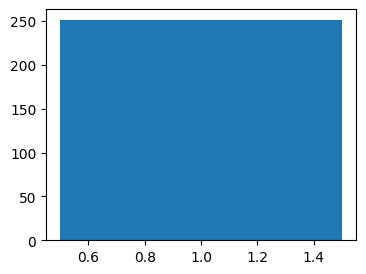

In [33]:
plot_histogram(markov_dict_words)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


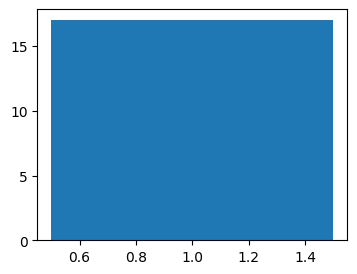

In [34]:
plot_histogram(markov_dict_words_LIACS)

<font size="4" color="#1E90FF"><b>Getting transition history along with histogram for Alice text where markov chain is word based</b></font>

Transition history:
transition 1 : 251 sequences


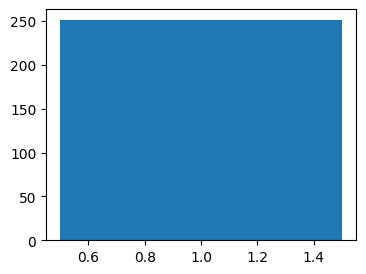

In [35]:
plot_histogram_upd(markov_dict_words)

Transition history:
transition 1 : 17 sequences


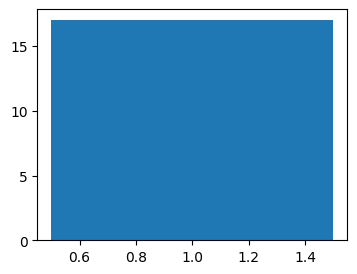

In [36]:
plot_histogram_upd(markov_dict_words_LIACS)

LIACS_text = "The LIACS staff is invited to a conference today - titled 'LIACS heroes' - in the general meeting room"

In [37]:
LIACS_text_repeating_phrases = "The LIACS staff is invited to a conference today - titled 'LIACS heroes' - in the general meeting room and the LIACS staff is invited to another conference today - titled 'LIACS champions'."


input_words_LIACS_repeating_phrases = LIACS_text_repeating_phrases.split()
markov_dict_words_LIACS_repeating_phrases = markov(input_words_LIACS_repeating_phrases, 4)
LIACS_output_words_repeating_phrases = ' '.join(generate(markov_dict_words_LIACS_repeating_phrases, 100))
print(textwrap.fill(LIACS_output_words_repeating_phrases, 80))

conference today - titled 'LIACS heroes' - in the general meeting room and the
LIACS staff is invited to another conference today - titled 'LIACS heroes' - in
the general meeting room and the LIACS staff is invited to a conference today -
titled 'LIACS champions'.


In [38]:
print(markov_dict_words_LIACS_repeating_phrases)

{('The', 'LIACS', 'staff'): ['is'], ('LIACS', 'staff', 'is'): ['invited', 'invited'], ('staff', 'is', 'invited'): ['to', 'to'], ('is', 'invited', 'to'): ['a', 'another'], ('invited', 'to', 'a'): ['conference'], ('to', 'a', 'conference'): ['today'], ('a', 'conference', 'today'): ['-'], ('conference', 'today', '-'): ['titled', 'titled'], ('today', '-', 'titled'): ["'LIACS", "'LIACS"], ('-', 'titled', "'LIACS"): ["heroes'", "champions'."], ('titled', "'LIACS", "heroes'"): ['-'], ("'LIACS", "heroes'", '-'): ['in'], ("heroes'", '-', 'in'): ['the'], ('-', 'in', 'the'): ['general'], ('in', 'the', 'general'): ['meeting'], ('the', 'general', 'meeting'): ['room'], ('general', 'meeting', 'room'): ['and'], ('meeting', 'room', 'and'): ['the'], ('room', 'and', 'the'): ['LIACS'], ('and', 'the', 'LIACS'): ['staff'], ('the', 'LIACS', 'staff'): ['is'], ('invited', 'to', 'another'): ['conference'], ('to', 'another', 'conference'): ['today'], ('another', 'conference', 'today'): ['-'], ('titled', "'LIACS",

In [39]:
for key, values in markov_dict_words_LIACS_repeating_phrases.items():
    if len(values) == 2:
        print(f"{key} : {values}")

('LIACS', 'staff', 'is') : ['invited', 'invited']
('staff', 'is', 'invited') : ['to', 'to']
('is', 'invited', 'to') : ['a', 'another']
('conference', 'today', '-') : ['titled', 'titled']
('today', '-', 'titled') : ["'LIACS", "'LIACS"]
('-', 'titled', "'LIACS") : ["heroes'", "champions'."]


Transition history:
transition 1 : 19 sequences
transition 2 : 6 sequences


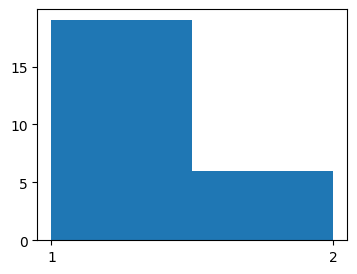

In [40]:
plot_histogram_upd(markov_dict_words_LIACS_repeating_phrases)

We can produce more variation by reducing the word-based n-gram order from 4 to 3, like this:

In [41]:
markov_dict_words = markov(input_words, 4)
output_words = ' '.join(generate(markov_dict_words, 100, "Alice was".split()))
print(textwrap.fill(output_words, 80))

whether the pleasure of making a daisy-chain would be worth the trouble of
getting up and picking the daisies, when suddenly a White Rabbit with pink eyes
ran close by her. There was nothing so very remarkable in that; nor did Alice
think it so very much out of the way to hear the Rabbit say to itself, `Oh dear!
Oh dear! I shall be late!' (when she thought it over afterwards, it occurred to
her that she ought to have wondered at this, but at the time it all seemed quite
natural); but when the Rabbit actually took a


In [42]:
markov_dict_words = markov(input_words, 3)
output_words = ' '.join(generate(markov_dict_words, 100, "Alice was".split()))
print(textwrap.fill(output_words, 80))

Alice was beginning to get very tired of sitting by her sister on the bank, and
of having nothing to do: once or twice she had never before seen a rabbit with
either a waistcoat-pocket, or a watch to take out of the way to hear the Rabbit
actually took a watch out of it, and then hurried on, Alice started to her that
she ought to have wondered at this, but at the time it all seemed quite
natural); but when the Rabbit actually took a watch out of it, and fortunately
was just in time to see it


<font size="4" color="#1E90FF"><b>Side by side comparison of different orders for word generation function - LIACS text</b></font>

In [43]:
markov_dict_words_LIACS = markov(input_words_LIACS, 4)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100, "staff is".split()))
print(textwrap.fill(LIACS_output_words, 80))

- in the general meeting room


In [44]:
markov_dict_words_LIACS = markov(input_words_LIACS, 3)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100, "staff is".split()))
print(textwrap.fill(LIACS_output_words, 80))

staff is invited to a conference today - titled 'LIACS heroes' - in the general
meeting room


In [45]:
markov_dict_words_LIACS = markov(input_words_LIACS, 4)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100))
print(textwrap.fill(LIACS_output_words, 80))

conference today - titled 'LIACS heroes' - in the general meeting room


In [46]:
markov_dict_words_LIACS = markov(input_words_LIACS, 3)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100))
print(textwrap.fill(LIACS_output_words, 80))

invited to a conference today - titled 'LIACS heroes' - in the general meeting
room


In [47]:
markov_dict_words_LIACS = markov(input_words_LIACS, 4)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100, "staff is invited".split()))
print(textwrap.fill(LIACS_output_words, 80))

staff is invited to a conference today - titled 'LIACS heroes' - in the general
meeting room


In [48]:
markov_dict_words_LIACS = markov(input_words_LIACS, 3)
LIACS_output_words = ' '.join(generate(markov_dict_words_LIACS, 100, "staff is".split()))
print(textwrap.fill(LIACS_output_words, 80))

staff is invited to a conference today - titled 'LIACS heroes' - in the general
meeting room


We can see that there are a few n-grams with different endings from the histogram of array lengths:

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


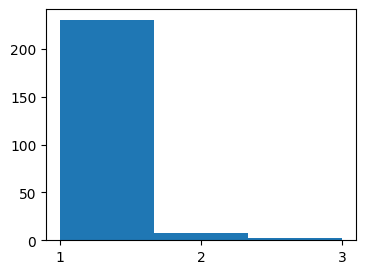

In [49]:
plot_histogram(markov_dict_words)

boy who cried wolf

In [82]:
boy_who_cried_wolf = """
In a quiet village surrounded by hills and green fields, there lived a young boy named Aiden. Aiden was a shepherd who took care of the village’s sheep. He was known for playing tricks and telling stories that sometimes stretched the truth. The villagers found his antics amusing but sometimes sighed in mild annoyance.

One sunny morning, as the sun painted the sky gold, Aiden watched over his sheep. The day passed peacefully, with the sheep bleating softly and the village humming in the distance.
As the sun began to set, Aiden got restless. A mischievous grin crossed his face as he thought of a prank. “What if I trick the villagers with a harmless joke?” he wondered, his eyes sparkling with mischief.
Aiden’s heart raced as he shouted, “Wolf! Wolf! There’s a wolf in the field!”

Hearing Aiden’s urgent cries, the villagers hurried to the field with their tools. But when they arrived, there was no wolf in sight. Aiden stood there, chuckling to himself.
The villagers, puzzled but amused, laughed and scolded him gently. “Aiden, you rascal,” they said playfully. “You shouldn’t cry wolf unless there really is one.”
Aiden nodded, pleased that his prank had worked. He enjoyed the attention from the villagers.
Weeks passed, and Aiden kept playing tricks. Whenever he was bored, he would shout, “Wolf!” Each time, the villagers would come running, but there was never a wolf. They started shaking their heads and saying, “There goes Aiden again.”
But one day, as Aiden watched over his sheep, a real danger appeared. A hungry wolf had come into the field, eyeing the sheep hungrily.

Aiden’s heart raced with fear. He realized that his tricks had made the villagers not trust him. Now, with a real wolf approaching, his cries for help meant nothing.
Panicking, Aiden screamed, “Wolf! Wolf! There’s a wolf, and this time it’s real!”
The villagers, used to Aiden’s pranks, heard him but didn’t believe him. They thought it was another joke.
As the wolf came closer, Aiden waved his arms and shouted desperately. But no one came to help. The wolf attacked the sheep, satisfied with its meal.
As the sun set, Aiden sat among the scattered sheep, filled with regret. His tricks had cost him the villagers’ trust and the lives of his sheep.

The villagers arrived, worried and unsure. “Aiden, is this another prank?” they asked cautiously.
Tears welled up in Aiden’s eyes as he shook his head. “No, this time it’s real. The wolf came, and I cried for help, but you didn’t believe me.”
The villagers looked at each other sadly, realizing their skepticism had led to tragedy. They mourned the loss of the sheep.
In the days that followed, Aiden learned a hard lesson about honesty and trust. He saw how his actions had consequences and understood the importance of telling the truth, especially when it mattered.
The villagers also learned to be more careful but to listen carefully to real calls for help. Over time, Aiden worked to earn back their trust through his actions and words.

And as the village moved forward, the story of the boy who cried wolf served as a reminder of the importance of honesty and the consequences of playing with trust.
"""


In [84]:
markov_dict_chars_boywolf = markov(boy_who_cried_wolf, 3)
print(textwrap.fill(str(markov_dict_chars_boywolf)[:960], 80))

{('\n', 'I'): ['n', 'n'], ('I', 'n'): [' ', ' '], ('n', ' '): ['a', 'f', 'w',
'f', 'm', 'p', 'w', 't', 'b', 't', 'g', 'c', 't', 't', 's', 's', 'n', 'f', 'k',
'a', 'w', 's', 'w', 's', 's', 'A', 't', 'l', 'a', 'i', 'c', 'w', 'b'], (' ',
'a'): [' ', 'n', ' ', ' ', 'n', 'n', 'm', 'n', 's', 'n', 's', ' ', ' ', 's', '
', 'r', 'm', 'n', 't', 'n', ' ', 'n', 'g', 's', ' ', 'p', ' ', 'p', ' ', 'n',
'n', 'r', 'n', 't', 'm', 'n', 'r', 'n', 'n', 's', 's', 'n', 't', ' ', 'b', 'n',
'c', 'n', 'l', 'c', 'n', 's', 's', ' ', 'n'], ('a', ' '): ['q', 'y', 's', 'p',
'h', 'w', 'w', 'r', 'r', 'w', 'h', 'r'], (' ', 'q'): ['u'], ('q', 'u'): ['i',
'e', 'e'], ('u', 'i'): ['e'], ('i', 'e'): ['t', 'l', 's', 'v', 'f', 'l', 's',
'd', 'l', 'l', 's', 'v', 'd', 'd', 'd', 'v', 'd'], ('e', 't'): [' ', 'i', 'c',
'i', ',', ',', '.'], ('t', ' '): ['v', 's', 's', 'r', 'o', 'i', 'r', 'c', 'w',
'a', 'c', 'h', 'p', 't', 'o', 'r', 'h', 't', 'h', 'n', 'd', 'b', 'i', 'w', 'n',
'a', 'h', 'a',


[2, 2, 33, 55, 12, 1, 3, 1, 17, 7, 36, 16, 16, 20, 28, 21, 18, 20, 79, 46, 6, 5, 5, 5, 19, 13, 21, 29, 54, 73, 16, 1, 21, 50, 27, 4, 81, 31, 6, 5, 33, 11, 32, 15, 6, 15, 10, 3, 5, 44, 87, 71, 98, 38, 10, 11, 4, 14, 3, 3, 25, 16, 4, 4, 7, 1, 8, 18, 18, 21, 24, 2, 26, 41, 10, 18, 16, 12, 1, 5, 4, 12, 16, 17, 6, 5, 5, 21, 10, 21, 15, 10, 19, 3, 10, 6, 5, 5, 2, 1, 9, 4, 1, 7, 16, 18, 14, 5, 8, 4, 30, 14, 17, 8, 9, 6, 11, 17, 20, 14, 16, 5, 5, 14, 14, 3, 9, 8, 16, 1, 9, 15, 14, 25, 7, 1, 2, 10, 3, 6, 2, 6, 16, 12, 5, 3, 1, 6, 10, 6, 15, 5, 1, 1, 11, 1, 5, 5, 3, 5, 4, 3, 3, 1, 3, 20, 13, 3, 8, 4, 8, 13, 4, 27, 11, 4, 4, 7, 11, 3, 9, 14, 12, 4, 1, 12, 1, 3, 5, 1, 1, 3, 5, 7, 3, 4, 2, 2, 3, 6, 15, 5, 2, 6, 5, 1, 7, 4, 1, 4, 3, 5, 9, 4, 1, 9, 4, 2, 1, 2, 2, 2, 1, 2, 3, 9, 1, 2, 4, 18, 13, 7, 9, 4, 3, 3, 2, 3, 8, 5, 5, 17, 5, 4, 3, 1, 3, 5, 1, 6, 1, 5, 4, 2, 3, 4, 3, 4, 1, 2, 6, 1, 1, 1, 1, 2, 6, 5, 6, 2, 2, 3, 13, 1, 1, 6, 1, 1, 1, 3, 3, 3, 1, 3, 1, 10, 4, 1, 4, 4, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1,

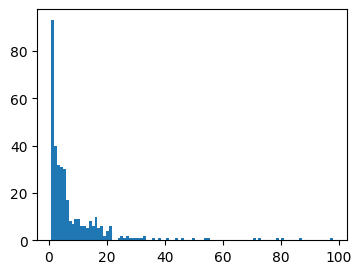

In [85]:
plot_histogram(markov_dict_chars_boywolf)

Transition history:
transition 1 : 93 sequences
transition 2 : 40 sequences
transition 3 : 32 sequences
transition 4 : 31 sequences
transition 5 : 30 sequences
transition 6 : 17 sequences
transition 7 : 8 sequences
transition 8 : 7 sequences
transition 9 : 9 sequences
transition 10 : 9 sequences
transition 11 : 6 sequences
transition 12 : 6 sequences
transition 13 : 5 sequences
transition 14 : 8 sequences
transition 15 : 6 sequences
transition 16 : 10 sequences
transition 17 : 5 sequences
transition 18 : 6 sequences
transition 19 : 2 sequences
transition 20 : 4 sequences
transition 21 : 6 sequences
transition 24 : 1 sequences
transition 25 : 2 sequences
transition 26 : 1 sequences
transition 27 : 2 sequences
transition 28 : 1 sequences
transition 29 : 1 sequences
transition 30 : 1 sequences
transition 31 : 1 sequences
transition 32 : 1 sequences
transition 33 : 2 sequences
transition 36 : 1 sequences
transition 38 : 1 sequences
transition 41 : 1 sequences
transition 44 : 1 sequences
tr

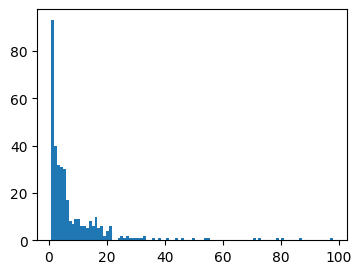

In [86]:
plot_histogram_upd(markov_dict_chars_boywolf)

Transition history:
transition 1 : 521 sequences
transition 2 : 231 sequences
transition 3 : 108 sequences
transition 4 : 79 sequences
transition 5 : 45 sequences
transition 6 : 23 sequences
transition 7 : 9 sequences
transition 8 : 5 sequences
transition 9 : 16 sequences
transition 10 : 8 sequences
transition 11 : 4 sequences
transition 12 : 3 sequences
transition 13 : 6 sequences
transition 15 : 5 sequences
transition 16 : 9 sequences
transition 17 : 3 sequences
transition 18 : 2 sequences
transition 19 : 2 sequences
transition 20 : 4 sequences
transition 21 : 3 sequences
transition 40 : 1 sequences
transition 49 : 2 sequences
transition 56 : 1 sequences


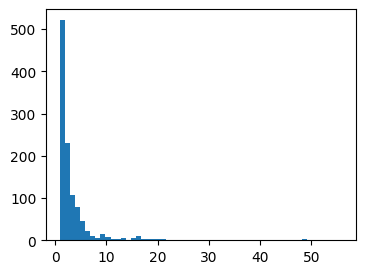

In [92]:
markov_dict_chars_boywolf_4 = markov(boy_who_cried_wolf, 4)
plot_histogram_upd(markov_dict_chars_boywolf_4)

when order is changed from 3 to 4 in there is a subtle change in sentence quality created but we can sense improvement

In [87]:
markov_dict_chars_boy = markov(boy_who_cried_wolf, 3)
output_text_boy = ''.join(generate(markov_dict_chars_boy))
print(textwrap.fill(output_text_boy, 80))

You dided a red ascame.”  Aid the wold Aiden surried hen’s tiond wolf trus sight
hared th tharne they ingreeks appecials theep, the bles a his tionsequiestactim.
The villagereal wout th their hillaganoyed, “Aid I tood sers. In min surne
theyes plagere’s ache villagerassed. “Wolf!” the shout to rusight. No, a
hisfielp honsunset, wolf sed, hingrick the eard to clost his ances nothers ated
th, wat his theas of unnod der his schis nothe eyess bellagers. “Thers wory wor
his ey a was wolf pratim. His


In [88]:
markov_dict_chars_boy = markov(boy_who_cried_wolf, 4)
output_text_boy = ''.join(generate(markov_dict_chars_boy))
print(textwrap.fill(output_text_boy, 80))

ldn’t cried his sight it’s eyes a realizing. Panicks. Wheneve mourned as known
forward his sheep. He wondered. “You didn’t be morning, and grin sating with
time tricks harms action fields, that sometime, chuckling with resty as known
from the field, especially. The field who trust himself. They mourned that him
gentics as known for playing, “They to trust the attered foundere was a realized
his of hone carefully, and his shout when its meantions ant cries, the sun
passed into lesson for prank?”


In [89]:
markov_dict = markov(boy_who_cried_wolf, 4)
output_text_boy = ''.join(generate(markov_dict, 1000, "vil"))
print(textwrap.fill(output_text_boy, 80))

villed sheep. The village’s reame, Aiden cross of the skeptics a prank?” hearned
with fear. He runny more lived, anot to to this eyes of that sometime, Aiden
kept playfully is the villagers no onesty and unsurroung that his pranks, the
shephere’s real day pain.” But you sheep. In the villagers. Weeks prank?” the
village’s prank. “No, the village morning, “Wolf! Wolf! Wolf in Aiden’s real
days tricking in storied wolf appeart rascal,” there, a real!” The was Aiden’s
hearned for prank?” the words. Weeks and shepher playing the lived and to the
village him genticism hard leased by his shout, Aiden’s and to tricks he vills
for hears he sheep, fillagers, the village moved to the worrives of they and
their trust hone day painto realls actiously. But yound to tricks. When stances
Aiden cries for he boy wolf! Wolf had come importance attere of the villagedy.
But disten there got race of hone day, realized for pranks, that softly. “Aiden
set, Aiden watched over to ser, Aiden it when waved, he f

In [90]:
input_words_Boy = boy_who_cried_wolf.split()
markov_dict_words_Boy = markov(input_words_Boy, 4)
Boy_output_words = ' '.join(generate(markov_dict_words_Boy, 100))
print(textwrap.fill(Boy_output_words, 80))

wolf in sight. Aiden stood there, chuckling to himself. The villagers, puzzled
but amused, laughed and scolded him gently. “Aiden, you rascal,” they said
playfully. “You shouldn’t cry wolf unless there really is one.” Aiden nodded,
pleased that his prank had worked. He enjoyed the attention from the villagers.
Weeks passed, and Aiden kept playing tricks. Whenever he was bored, he would
shout, “Wolf!” Each time, the villagers would come running, but there was never
a wolf. They started shaking their heads and saying, “There goes Aiden again.”
But one day, as Aiden watched over his sheep, a real danger


[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

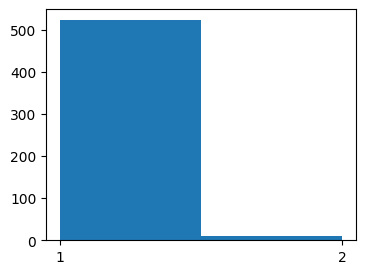

In [91]:
plot_histogram(markov_dict_words_Boy)

wondered, his eyes sparkling with mischief. Aiden’s heart raced with fear. He
realized that his tricks had made the villagers hurried to the field with their
tools. But when they arrived, there was no wolf in sight. Aiden stood there,
chuckling to himself. The villagers, puzzled but amused, laughed and scolded him
gently. “Aiden, you rascal,” they said playfully. “You shouldn’t cry wolf unless
there really is one.” Aiden nodded, pleased that his prank had worked. He
enjoyed the attention from the villagers. Weeks passed, and Aiden kept playing
tricks. Whenever he was bored, he would shout, “Wolf!” Each time,
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 3, 2, 1, 1, 2, 1, 1, 3, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2,

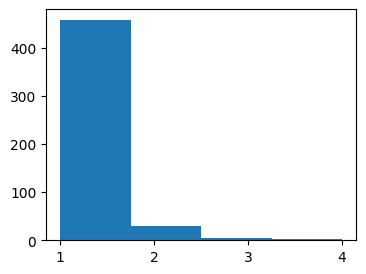

In [95]:
input_words_Boy = boy_who_cried_wolf.split()
markov_dict_words_Boy_3 = markov(input_words_Boy, 3)
Boy_output_words = ' '.join(generate(markov_dict_words_Boy_3, 100))
print(textwrap.fill(Boy_output_words, 80))

plot_histogram(markov_dict_words_Boy_3)

But a better solution is to provide a longer input text, which we'll do in the next section.

### Kafgenstein

In this section we're going to explore how we can generate original text using a Markov chain by combining data sources. This exercise is inspired by the [Kafgenstein example](https://rednoise.org/rita/examples/p5/Kafgenstein/) developed for the RiTa library for Java/Processing and Javascript.

For this exercise, we will upload files to the Colab runtime.

> *Note that these files will be deleted when the runtime closes, either because the window is closed intentionally or due to inactivity. If this happens, you will need to reupload the files.*

Start by downloading the following files to your computer:

- [kafka.txt](https://rednoise.org/rita/examples/data/kafka.txt)
- [wittgenstein.txt](https://rednoise.org/rita/examples/data/wittgenstein.txt)

Next, upload these files to the Colab runtime: open the files area in the left sidebar on the left by clicking on the folder icon. Then upload the files by either (1) dragging and dropping the files from your computer into the Colab files area; or (2) clicking on the document icon to open a file dialog and select the files on your computer to upload.

We can now load the contents of these files into variables:

In [50]:
kafka_file = open("/content/kafka_hw.txt", 'r')
# if your working on a local copy of this notebook
# provide a relative path these text files, e.g.:
# kafka_file = open("./content/kafka.txt", 'r')
kafka_text = kafka_file.read()
# Print a short extract from the start of the file
print(textwrap.fill(kafka_text[:960], 80))

One morning, when Gregor Samsa woke from troubled dreams, he found himself
transformed in his bed into a horrible vermin. He lay on his armour-like back,
and if he lifted his head a little he could see his brown belly, slightly domed
and divided by arches into stiff sections. The bedding was hardly able to cover
it and seemed ready to slide off any moment. His many legs, pitifully thin
compared with the size of the rest of him, waved about helplessly as he looked.
"What's happened to me?" he thought. It wasn't a dream. His room, a proper human
room although a little too small, lay peacefully between its four familiar
walls. A collection of textile samples lay spread out on the table - Samsa was a
travelling salesman - and above it there hung a picture that he had recently cut
out of an illustrated magazine and housed in a nice, gilded frame. It showed a
lady fitted out with a fur hat and fur boa who sat upright, raising a heavy fur
muff that cov


In [51]:
wittgenstein_file = open("/content/wittgenstein_hw.txt", 'r')
# if your working on a local copy of this notebook
# provide a relative path these text files, e.g.:
# wittgenstein_file = open("./content/wittgenstein.txt", 'r')
wittgenstein_text = wittgenstein_file.read()
# Print a short extract from the start of the file
print(textwrap.fill(wittgenstein_text[:960], 80))

Perhaps this book will be understood only by someone who has himself already had
the thoughts that are expressed in it--or at least similar thoughts.--So it is
not a textbook.--Its purpose would be achieved if it gave pleasure to one person
who read and understood it.  The book deals with the problems of philosophy, and
shows, I believe, that the reason why these problems are posed is that the logic
of our language is misunderstood. The whole sense of the book might be summed up
the following words: what can be said at all can be said clearly, and what we
cannot talk about we must pass over in silence.  Thus the aim of the book is to
draw a limit to thought, or rather--not to thought, but to the expression of
thoughts: for in order to be able to draw a limit to thought, we should have to
find both sides of the limit thinkable i.e. we should have to be able to think
what cannot be thought.  It will therefore only be in language that the limit
can


We can now generate a new text by supplying the `markov()` function with a concatenation of the source texts. If we don't supply some starting text (or one that is not of the required length or does not appear in the input text) then the function will start with a random n-gram.

In [52]:
kafgenstein_input = kafka_text + wittgenstein_text
kafgenstein_markov_chars = markov(kafgenstein_input, 10)
kafgenstein_output = ''.join(generate(kafgenstein_markov_chars, 960))
print(textwrap.fill(kafgenstein_output, 80))

ophy can talk about any of the spots in our picture and of least action' before
the first to get enough now; dressed in a smart blue uniform coat; his mother
dissuade her. Gregor, the chief clerk had already contain the expression of
agreement or its sense. A propositional variable is. The stipulation of lighter
to darker. It is the form 'aRb' strikes us as a picture.  In a proposition.
"Getting up now." The change in Gregor's not being there was no surprise even
himself through the door of Gregor was already the end-points of the
proposition, 'All roses are either proposition shows how little is achieved
quite easily produced is not essential to a name.  Although they were indeed
suffering enough.  It was impossible to speak: for the last an adjectives, and
conjunctions, as soon as she was in danger of losing his head in front of her
and they must have certainty, possibility of a logical place of the present
circumstances I call truth-functions


If we supply some valid starting text, we can have a bit more control over the output:

In [53]:
kafgenstein_output = ''.join(generate(kafgenstein_markov_chars, 960, "philosoph"))
print(textwrap.fill(kafgenstein_output, 80))

philosophy aims at the step from one fact p infinite temporal objects' or
'logical combinations in their chairs reading a number of the family at home for
the time before and the world.  Proposition. But the loudest complaints, and
it's almost in a frenzy, when he heard his father soon appears in physics: more
or less identical' means no more a component part of the questions to elementary
propositions; for in a suitable crate with a sense, provided that this is the
foundation of depicting.  If, for example, the following process: we produce
them out onto the centre of the thoughts is a picture the picture.  Every
proposition. This product, therefore, to introduction of elementary proposition.
For equations by mere inspection of a determine a logic given the results of all
that is how thin he was at home, and only they had been occupied with the idea
that the number of propositions.  All that is to say of two things: they are
intended to send her


#### Word-based Kafgenstein

We can use the same approach as before to create a word-based Markov chain and use this to generate text:

In [76]:
kafgenstein_words = kafgenstein_input.split(' ')
kafgenstein_markov_words = markov(kafgenstein_words, 3)
kafgenstein_output = ' '.join(generate(kafgenstein_markov_words, 100))
print(textwrap.fill(kafgenstein_output, 80))

of her in by the family had been working for them, swayed gently in all possible
situations, and latter none. In a certain proposition, then with it the chance
to go very slowly. Meanwhile Gregor's sister also had to do so, but as time went
by Gregor crawling about the home, every other day would be quite possible for
someone to be at every door of the clothing it is impossible to assert that a
proposition had a formal property as to form propositions that have different
modes of signification: that is required is that there was not a lot, but it was
so


We can also still supply a starting text, remembering to split it into words:

In [78]:
kafgenstein_output = ' '.join(generate(kafgenstein_markov_words, 100, "Gregor Samsa".split()))
print(textwrap.fill(kafgenstein_output, 80))

Gregor Samsa woke from it when it was money that Gregor awoke from his father's
debt to his parents about the world is completely described by giving all
elementary propositions: then I can imagine empty, but I came near to giving him
my word of the names are suitably chosen. It is quite correct; only it cannot be
said , but makes itself manifest in the room several times a day. And despite
this condition, he was looking out the window open from then on it without
losing what was essential to the task of swinging the entire flat and force us
to set


As we can see from the histogram there are plenty of n-grams with multiple endings, some with a very large number.

[1, 1, 4, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 40, 2, 1, 13, 2, 1, 1, 1, 4, 24, 1, 1, 1, 7, 31, 1, 2, 27, 1, 23, 1, 50, 8, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 36, 1, 1, 7, 2, 1, 3, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 3, 41, 1, 3, 257, 3, 3, 2, 1, 1, 1, 1, 45, 1, 1, 6, 1, 1, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 3, 4, 71, 13, 1, 1, 1, 18, 2, 1, 1, 6, 1, 2, 5, 1, 1, 20, 1, 49, 81, 2, 1, 1, 45, 19, 1, 1, 1, 1, 1, 51, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 36, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 22, 8, 12, 1, 1, 1, 7, 1, 1, 1, 1, 10, 2, 6, 15, 2, 56, 1, 1, 1, 1, 1, 1, 20, 4, 1, 2, 1, 1, 4, 7, 5, 1, 1, 1, 1, 2, 4, 1, 1, 2, 1, 1, 1, 1, 6, 1, 1, 4, 1, 7, 17, 8, 1, 64, 1, 10, 34, 1, 7, 2, 17, 1, 1, 3, 1, 9, 5, 1, 1, 2, 4, 1, 1, 1, 1, 1, 1, 2, 3, 1, 1, 1, 1, 1, 12, 2, 14, 2, 2, 3, 21, 1, 1, 2, 1, 1, 1, 1, 10, 1, 31, 1, 3, 35, 7, 1, 1, 1, 6, 1, 2, 24, 5, 15, 4, 3, 1, 1, 1, 1, 1, 11, 1, 1, 1, 1, 1, 1, 1, 1, 1, 60, 23, 1, 1, 1, 1, 1, 4, 1, 1, 1

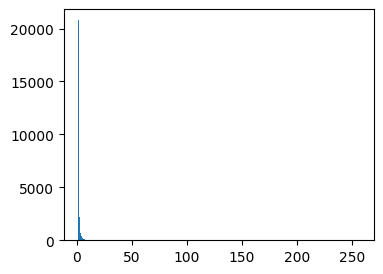

In [79]:
plot_histogram(kafgenstein_markov_words)

<font size="4" color="#1E90FF"><b>Jane austen and shakespeare experiments</b></font>

In [96]:
jane_austen = """It is a truth universally acknowledged, that a single man in
possession of a good fortune, must be in want of a wife.
However little known the feelings or views of such a man
may be on his first entering a neighbourhood, this truth is so
well fixed in the minds of the surrounding families, that he
is considered as the rightful property of some one or other of
their daughters.
“My dear Mr. Bennet,” said his lady to him one day, “have
you heard that Netherfield Park is let at last?”
Mr. Bennet replied that he had not.
“But it is,” returned she; “for Mrs. Long has just been here,
and she told me all about it.”
Mr. Bennet made no answer.
“Do not you want to know who has taken it?” cried his
wife impatiently.
“You want to tell me, and I have no objection to hearing it.”
This was invitation enough.
“Why, my dear, you must know, Mrs. Long says that
Netherfield is taken by a young man of large fortune from
the north of England; that he came down on Monday in a
chaise and four4 to see the place, and was so much delighted
with it that he agreed with Mr. Morris immediately; that he
is to take possession before Michaelmas, and some of his
servants are to be in the house by the end of next week.”
“What is his name?”
“Bingley.” """

In [97]:
shakespeare = """
Hermia and Lysander were lovers; but Hermia's father wished her to marry another man, named Demetrius.

Now, in Athens, where they lived, there was a wicked law, by which any girl who refused to marry according to her father's wishes, might be put to death. Hermia's father was so angry with her for refusing to do as he wished, that he actually brought her before the Duke of Athens to ask that she might be killed, if she still refused to obey him. The Duke gave her four days to think about it, and, at the end of that time, if she still refused to marry Demetrius, she would have to die.

Lysander of course was nearly mad with grief, and the best thing to do seemed to him for Hermia to run away to his aunt's house at a place beyond the reach of that cruel law; and there he would come to her and marry her. But before she started, she told her friend, Helena, what she was going to do.

Helena had been Demetrius' sweetheart long before his marriage with Hermia had been thought of, and being very silly, like all jealous people, she could not see that it was not poor Hermia's fault that Demetrius wished to marry her instead of his own lady, Helena. She knew that if she told Demetrius that Hermia was going, as she was, to the wood outside Athens, he would follow her, "and I can follow him, and at least I shall see him," she said to herself. So she went to him, and betrayed her friend's secret.

Now this wood where Lysander was to meet Hermia, and where the other two had decided to follow them, was full of fairies, as most woods are, if one only had the eyes to see them, and in this wood on this night were the King and Queen of the fairies, Oberon and Titania. Now fairies are very wise people, but now and then they can be quite as foolish as mortal folk. Oberon and Titania, who might have been as happy as the days were long, had thrown away all their joy in a foolish quarrel. They never met without saying disagreeable things to each other, and scolded each other so dreadfully that all their little fairy followers, for fear, would creep into acorn cups and hide them there.

So, instead of keeping one happy Court and dancing all night through in the moonlight as is fairies' use, the King with his attendants wandered through one part of the wood, while the Queen with hers kept state in another. And the cause of all this trouble was a little Indian boy whom Titania had taken to be one of her followers. Oberon wanted the child to follow him and be one of his fairy knights; but the Queen would not give him up.

On this night, in a mossy moonlit glade, the King and Queen of the fairies met.

"Ill met by moonlight, proud Titania," said the King.

"What! jealous, Oberon?" answered the Queen. "You spoil everything with your quarreling. Come, fairies, let us leave him. I am not friends with him now."

"It rests with you to make up the quarrel," said the King.

"Give me that little Indian boy, and I will again be your humble servant and suitor."

"Set your mind at rest," said the Queen. "Your whole fairy kingdom buys not that boy from me. Come, fairies."

And she and her train rode off down the moonbeams.

"Well, go your ways," said Oberon. "But I'll be even with you before you leave this wood."

Then Oberon called his favorite fairy, Puck. Puck was the spirit of mischief. He used to slip into the dairies and take the cream away, and get into the churn so that the butter would not come, and turn the beer sour, and lead people out of their way on dark nights and then laugh at them, and tumble people's stools from under them when they were going to sit down, and upset their hot ale over their chins when they were going to drink.

"Now," said Oberon to this little sprite, "fetch me the flower called Love-in-idleness. The juice of that little purple flower laid on the eyes of those who sleep will make them, when they wake, to love the first thing they see. I will put some of the juice of that flower on my Titania's eyes, and when she wakes she will love the first thing she sees, were it lion, bear, or wolf, or bull, or meddling monkey, or a busy ape."

While Puck was gone, Demetrius passed through the glade followed by poor Helena, and still she told him how she loved him and reminded him of all his promises, and still he told her that he did not and could not love her, and that his promises were nothing. Oberon was sorry for poor Helena, and when Puck returned with the flower, he bade him follow Demetrius and put some of the juice on his eyes, so that he might love Helena when he woke and looked on her, as much as she loved him. So Puck set off, and wandering through the wood found, not Demetrius, but Lysander, on whose eyes he put the juice; but when Lysander woke, he saw not his own Hermia, but Helena, who was walking through the wood looking for the cruel Demetrius; and directly lie saw her he loved her and left his own lady, under the spell of the purple flower.

When Hermia woke she found Lysander gone, and wandered about the wood trying to find him. Puck went back and told Oberon what lie had done, and Oberon soon found that he had made a mistake, and set about looking for Demetrius, and having found him, put some of the juice on his eyes. And the first thing Demetrius saw when he woke was also Helena. So now Demetrius and Lysander were both following her through the wood, and it was Hermia's turn to follow her lover as Helena had done before. The end of it was that Helena and Hermia began to quarrel, and Demetrius and Lysander went off to fight. Oberon was very sorry to see his kind scheme to help these lovers turn out so badly. So he said to Puck--

"These two young men are going to fight. You must overhang the night with drooping fog, and lead them so astray, that one will never find the other. When they are tired out, they will fall asleep. Then drop this other herb on Lysander's eyes. That will give him his old sight and his old love. Then each man will have the lady who loves him, and they will all think that this has been only a Midsummer Night's Dream. Then when this is done, all will be well with them."

So Puck went and did as he was told, and when the two had fallen asleep without meeting each other, Puck poured the juice on Lysander's eyes, and said:--

"When thou wakest,
Thou takest

True delight

In the sight

Of thy former lady's eye:

Jack shall have Jill;

Nought shall go ill."

Meanwhile Oberon found Titania asleep on a bank where grew wild thyme, oxlips, and violets, and woodbine, musk-roses and eglantine. There Titania always slept a part of the night, wrapped in the enameled skin of a snake. Oberon stooped over her and laid the juice on her eyes, saying:--

"What thou seest when thou wake,
Do it for thy true love take."

Now, it happened that when Titania woke the first thing she saw was a stupid clown, one of a party of players who had come out into the wood to rehearse their play. This clown had met with Puck, who had clapped an ass's head on his shoulders so that it looked as if it grew there. Directly Titania woke and saw this dreadful monster, she said, "What angel is this? Are you as wise as you are beautiful?"

"If I am wise enough to find my way out of this wood, that's enough for me," said the foolish clown.

"Do not desire to go out of the wood," said Titania. The spell of the love-juice was on her, and to her the clown seemed the most beautiful and delightful creature on all the earth. "I love you," she went on. "Come with me, and I will give you fairies to attend on you."

So she called four fairies, whose names were Peaseblossom, Cobweb, Moth, and Mustardseed.

"You must attend this gentleman," said the Queen. "Feed him with apricots and dewberries, purple grapes, green figs, and mulberries. Steal honey-bags for him from the bumble-bees, and with the wings of painted butterflies fan the moonbeams from his sleeping eyes."

"I will," said one of the fairies, and all the others said, "I will."

"Now, sit down with me," said the Queen to the clown, "and let me stroke your dear cheeks, and stick musk-roses in your smooth, sleek head, and kiss your fair large ears, my gentle joy."

"Where's Peaseblossom?" asked the clown with the ass's head. He did not care much about the Queen's affection, but he was very proud of having fairies to wait on him. "Ready," said Peaseblossom.

"Scratch my head, Peaseblossom," said the clown. "Where's Cobweb?" "Ready," said Cobweb.

"Kill me," said the clown, "the red bumble-bee on the top of the thistle yonder, and bring me the honey-bag. Where's Mustardseed?"

"Ready," said Mustardseed.

"Oh, I want nothing," said the clown. "Only just help Cobweb to scratch. I must go to the barber's, for methinks I am marvelous hairy about the face."

"Would you like anything to eat?" said the fairy Queen.

"I should like some good dry oats," said the clown--for his donkey's head made him desire donkey's food--"and some hay to follow."

"Shall some of my fairies fetch you new nuts from the squirrel's house?" asked the Queen.

"I'd rather have a handful or two of good dried peas," said the clown. "But please don't let any of your people disturb me; I am going to sleep."

Then said the Queen, "And I will wind thee in my arms."

And so when Oberon came along he found his beautiful Queen lavishing kisses and endearments on a clown with a donkey's head.

And before he released her from the enchantment, he persuaded her to give him the little Indian boy he so much desired to have. Then he took pity on her, and threw some juice of the disenchanting flower on her pretty eyes; and then in a moment she saw plainly the donkey-headed clown she had been loving, and knew how foolish she had been.

Oberon took off the ass's head from the clown, and left him to finish his sleep with his own silly head lying on the thyme and violets.

Thus all was made plain and straight again. Oberon and Titania loved each other more than ever. Demetrius thought of no one but Helena, and Helena had never had any thought of anyone but Demetrius.

As for Hermia and Lysander, they were as loving a couple as you could meet in a day's march, even through a fairy wood.

So the four mortal lovers went back to Athens and were married; and the fairy King and Queen live happily together in that very wood at this very day."""

In [98]:
janepeare_input = jane_austen + shakespeare
janepeare_markov_chars = markov(janepeare_input, 10)
janepeare_output = ''.join(generate(janepeare_markov_chars, 960))
print(textwrap.fill(janepeare_output, 80))

feelings or views of such a man may be on his eyes. And the first thing she
sees, were it lion, bear, or wolf, or bull, or meddling monkey, or a busy ape."
While Puck was gone, Demetrius and Lysander, on whose eyes he put the juice; but
when Lysander's eyes. That will give him his old love. Then he took pity on her,
and that he had made a mistake, and set about looking for the cruel Demetrius
thought of no one but Helena, who was walking through the wood looking for the
cruel Demetrius that Hermia woke she found Lysander gone, and was so much
delighted with it that he did not care much about the Queen with her for
refusing to do seemed the most beautiful?"  "If I am wise enough to find him.
Puck went and did as he was told, and when Puck returned she; “for Mrs. Long has
just been here, and she told me all about it.” Mr. Bennet,” said his lady to him
one day, “have you heard that Netherfield Park is let at last?” Mr. Bennet,”
said his lady to him


In [99]:
janepeare_output = ''.join(generate(janepeare_markov_chars, 960, "enchantme"))
print(textwrap.fill(janepeare_output, 80))

enchantment, he persuaded her to marry Demetrius and put some of my fairies are
very wise people, she could not see that it was not poor Hermia to run away to
his aunt's house at a place beyond the reach of that time, if she still refused
to obey him. The Duke gave her four days to think about it.” Mr. Bennet,” said
his lady to him one day, “have you heard that Netherfield is taken by a young
man of large fortune from the north of England; that he is considered as the
rightful property of some one or other of their daughters. “My dear Mr. Bennet,”
said his lady to him one day, “have you heard that Netherfield Park is let at
last?” Mr. Bennet replied that he actually brought her before the Duke of Athens
to ask that she might love Helena when he woke and looked on her, as much as she
loved him. So Puck set off, and wandering through the wood looking for the cruel
Demetrius saw when he woke was also Helena. So now Demetrius; and directly lie
saw he


In [100]:
janepeare_words = janepeare_input.split(' ')
janepeare_markov_words = markov(janepeare_words, 3)
janepeare_output = ' '.join(generate(janepeare_markov_words, 100))
print(textwrap.fill(janepeare_output, 80))

when they were as loving a couple as you are beautiful?"  "If I am wise enough
to find him. Puck went and did as he was very proud of having fairies to attend
on you."  So she called four fairies, whose names were Peaseblossom, Cobweb,
Moth, and Mustardseed.  "You must attend this gentleman," said the King.  "Give
me that little purple flower laid on the thyme and violets.  Thus all was made
plain and straight again. Oberon and Titania, who might have been as happy as
the days were long, had thrown away all their little fairy followers, for fear,
would creep into acorn cups


In [101]:
janepeare_output = ' '.join(generate(janepeare_markov_words, 100, "Demetrius passed".split()))
print(textwrap.fill(janepeare_output, 80))

Demetrius passed through the wood outside Athens, he would follow her, "and I
can follow him, and they will all think that this has been only a Midsummer
Night's Dream. Then when this is done, all will be well with them."  So Puck
went back to Athens and were married; and the fairy King and Queen of the
fairies met.  "Ill met by moonlight, proud Titania," said the clown. "But please
don't let any of your people disturb me; I am wise enough to find my way out of
this wood, that's enough for me," said the Queen. "You spoil everything with


[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 14, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 7, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 2, 1, 1, 1, 2, 3, 1, 1, 1, 1, 1, 1, 1, 1, 3, 2, 1, 1, 1, 2, 1, 1, 2, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

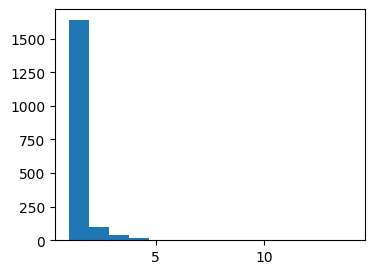

In [102]:
plot_histogram(janepeare_markov_words)

> ### Part 1: Ungraded Exercises
>
> Here are some ideas for experimenting with the Markov chain model developed here:
>
> - Experiment with the value for `order` to see how this changes the quality of the text produced for both character-based generation and word-based generation
> - Experiment with the length of the input text and how this impacts the diversity of output texts
>
> ### Part 1: Graded Exercise
>
> - Experiment with different input texts by uploading them to your runtime and then using them to generate new texts. Experiment with combining different texts together to form interesting mixtures.
>
> Submit a notebook with the code for your experiments and comments on the things that you tried. Include in your submission any text files that your notebook relies on.

## Part 2: Mario Jazz

In this second part of the homework assignment, we're going to use a Markov chain to use them to produce music.

## Getting Started

For this part of the assignment we're going to use iPyTone to build a synthesizer to play the notes generated by a Markov chain. iPyTone provides all of the necessary features that we need for this, including the difficult task of precisely scheduling the plackback of individual notes in a track that may have hundreds of notes.

First, we need to install the required packages if they're not already available:

In [1]:
# Install iPyTone if not already installed
!pip install ipytone

import ipytone
import random
import time
import ipytone

You should consider upgrading via the '/Users/fizzausman/markov_env/bin/python3 -m pip install --upgrade pip' command.


### Creating a Simple Synthesizer

Let's start by creating a basic synthesizer similar to what we would create with iPyTone. We'll use a simple oscillator with an amplitude envelope to create "chiptune" style sounds.

> **Note:** If you're developing in a local copy of this notebook, iPyTone will note generate sound if your using VSCode, use Jupyter Lab instead if you want to hear your tunes.

In [3]:
# create a synth and connect it to the main audio output
synth = ipytone.Synth().to_destination()
# play a middle 'C' for the duration of an 8th note
synth.trigger_attack_release("C4", "8n")

Synth()

The first line of code builds a synthesizer, with a single oscillator. An oscillator produces wave patterns that define the timbre of a note. The second line plays a note. The pitch of the note is defined by the first string `"C4"`, which is standard MIDI notation for middle C on a piano keyboard, i.e., note C in the 4th octave. The duration of the note is defined by the second string `"8n"`, which stands for an 8th note. iPyTone defines various different formats for defining time.

### Playing a Tune

iPyTone provides a number of features for playing scheduling events. All of its features are based on the core functionality provided by `ipytone.transport`, which implements a high-resolution timer for calling functions. The `ipytone.Part` class provides a convenient way to schedule playing notes with different pitches and durations, which is ideal for our purpose.

To use `ipytone.Part` we need to provide a function that will play a note when called, and an array of objects that provide (at least) the time and the pitch of the note that should be played. To illustrate, we'll define a function to play a note based on two parameters. The `play()` function takes `time` and `note` parameters; the `time` parameter defines the absolute time in the future when the note should be played. This is necessary because the function may be called ahead of the time when the note needs to be played, fortunately we can just pass this on to the `trigger_attack_release()` function without modification and it will play the note at that time in the future. The `note` parameter is one of the objects in the notes array that was passed to `ipytone.Part`. To make use of this information the function uses the `note.note` and `note.duration` values.


In [4]:
# define a function to play a single note
def play(time, note):
    synth.trigger_attack_release(
        note.note, note.duration, time=time, velocity=note.velocity)

We can then schedule the rhythm of the notes we want to play using an array of objects. Each object has a single property `time` with a formatted string value. The format of the string is `"b:q:s"`, where `b` is the bar, `q` is the quarter notes within the bar, and `s` is the sixteenths notes within the quarter. The location of a note using this notation is the sum of the bars, quarter notes and sixteenth notes. For example:

> `"4:3:2"` = 4 bars + 3 quarter notes + 2 sixteen notes

This is a natural notation for translating from sheet music, or from a sequencer like [Beepbox](https://www.beepbox.co/), but as we'll see this presents some problems for a Markov chain.

In [5]:
notes = [
  {"time": "0:0:0",  "note": "C4",  "duration": "2i"},
  {"time": "0:0:2",  "note": "C4",  "duration": "2i"},
  {"time": "0:1:2",  "note": "C4",  "duration": "2i"},
  {"time": "0:2:2",  "note": "C4",  "duration": "2i"},
  {"time": "0:3:0",  "note": "C4",  "duration": "2i"},
  {"time": "1:0:0",  "note": "C4",  "duration": "2i"},
  {"time": "1:2:0",  "note": "C4",  "duration": "4i"}
]

Before we can play the part we need to start the `ipytone.transport`, which will schedule the playing of the notes defined through the `ipytone.Part`. While we're setting up the transport, we can set the BPM to an appropriate value.

In [6]:
t = ipytone.transport
t.bpm.value = 206
t.start()

Transport()

To play the part we simply need to setup a synth and then provide the `play()` function and `notes` array to the constructor for `ipytone.Part`. Then we need to tell the part when to start playing.

In [7]:
part = ipytone.Part(play, notes)
part.start()

Part()

To play notes with different pitches and durations, we can add information to the dictionaries in the `notes` array. Each note object will be passed to the `play()` function. In the following the `note` is defined with a pitch as a string using the MIDI notation for notes that we used before, and duration is defined by duration with a value that is a string using a tick-based time length as defined by iPyTone.

In [8]:
notes = [
  {"time": "0:0:0",  "note": "E5",  "duration": "2i"},
  {"time": "0:0:2",  "note": "E5",  "duration": "2i"},
  {"time": "0:1:2",  "note": "E5",  "duration": "2i"},
  {"time": "0:2:2",  "note": "C5",  "duration": "2i"},
  {"time": "0:3:0",  "note": "E5",  "duration": "2i"},
  {"time": "1:0:0",  "note": "G5",  "duration": "2i"},
  {"time": "1:2:0",  "note": "G4",  "duration": "4i"}
]

We can define a part and start it at the same time to hear the result of these changes:

In [9]:
part = ipytone.Part(play, notes).start()

### Representing Notes for a Markov Chain

For this part of the homework assignment, we're going to see how we can use RiTa's implementation of a Markov chain, as used above, but in this case we're going to need to make sure that the input is formatted appropriately for a library that it primarily intended for natural language.

#### Representing Notes as Token Strings

The input to the Markov chain will still need to be in the form of a sequence of tokens, for convenience of editing we will work with arrays of strings representing notes. The Markov chain requires that the notes are represented as a sequence of notes with no global dependencies. Unfortunately, the object notation used by `ipytone.Part` is not appropriate because the time signatures for notes are defined in absolute terms, i.e., bars + quarters + sixteenths from the start of the sequence, rather than relative to the previous note. To get around this problem, we'll define a different format for defining a sequence of notes in relative terms as a string of tokens. The essential information for a note is pitch and duration, so our tokens should carry this information. We're going to use formatted strings of the form `"PP:DD"`, where `PP` is the pitch in MIDI note notation and `DD` is the duration in ticks (sixteenth notes). Consequently, the first three notes from the above example can be represented as `"E5:02"`. We could then write the token array for the tune above as:

In [65]:
tokens = [
    "E5:02",
    "E5:02",
    "E5:02",
    "C5:02",
    "E5:02",
    "G5:02",
    "G4:04"
]

To convert from this notation to a set of objects suitable to passing to the `ipytone.Part` class, we can define the following `convert_tokens_to_notes()` function:

In [66]:
def convert_tokens_to_notes(tokens):
    s = q = b = 0
    notes = []
    for token in tokens:
        note, duration = token.split(':')
        duration = int(duration)
        notes.append({
            'time': f"{b}:{q}:{s}",
            'note': note,
            'duration': f"{duration}i"
        })
        s += duration
        q, s = q + s // 4, s % 4
        b, q = b + q // 4, q % 4
    return notes

This function takes an array of tokens and steps through each token, split it using the `:` character that separates the `note` (pitch) from the `duration`. The time for starting each note is tracked using the variables `s`, `q` and `b`, which represent the sixteenth notes, quarter notes and bars that we need to write the required time signatures for the notes. Using these values a note object is constructed and appended to the array of notes. The values of `s`, `q` and `b` are then updated. The duration of each note in ticks, which is equivalent to sixteenths, so we add the note duration to `s`. There are 4 sixteenths per quarter. We propagate the update by adding the number of quarters represented by `s` to `q`, this is done by the following `q, s = q + s // 4, s % 4`, where the remainder is retained in `s`. The current bar is then similarly updated because there are 4 quarters in a bar, i.e., `b, q = b + q // 4, q % 4`.

Using this function we can convert an array of tokens to an array of notes:

In [67]:
convert_tokens_to_notes(tokens)

[{'time': '0:0:0', 'note': 'E5', 'duration': '2i'},
 {'time': '0:0:2', 'note': 'E5', 'duration': '2i'},
 {'time': '0:1:0', 'note': 'E5', 'duration': '2i'},
 {'time': '0:1:2', 'note': 'C5', 'duration': '2i'},
 {'time': '0:2:0', 'note': 'E5', 'duration': '2i'},
 {'time': '0:2:2', 'note': 'G5', 'duration': '2i'},
 {'time': '0:3:0', 'note': 'G4', 'duration': '4i'}]

In [68]:
notes = convert_tokens_to_notes(tokens)
part = ipytone.Part(play, notes).start()

Clearly, this isn't quite right. The missing information are the rests between notes.

#### Playing the Notes that Aren't There

To add this information we can define tokens to represent rests with durations, we'll use the string `"ZZ"` to represent a rest "note". Using this representation, we can define the tune using the following array:

In [69]:
tokens = [
   "E5:02",
   "E5:02", "ZZ:02",
   "E5:02", "ZZ:02",
   "C5:02",
   "E5:02", "ZZ:02",
   "G5:02", "ZZ:06",
   "G4:04", "ZZ:04",
]

We then just need to update the conversion function that converts tokens to notes to only add notes that do not define a rest:

In [70]:
def convert_tokens_to_notes(tokens):
    s = q = b = 0
    notes = []
    for token in tokens:
        note, duration = token.split(':')
        duration = int(duration)
        if note != "ZZ":
            notes.append({
                'time': f"{b}:{q}:{s}",
                'note': note,
                'duration': f"{duration}i"
            })
        s += duration
        q, s = q + s // 4, s % 4
        b, q = b + q // 4, q % 4
    return notes

Here's what the tune sounds like with the rests:

In [71]:
part = ipytone.Part(play, convert_tokens_to_notes(tokens)).start()

Finally, we can use this representation to generate a Markov chain but to be interesting we'll need a longer sequence of tokens:

In [72]:
mario_tokens = [
   "E5:02",
   "E5:02", "ZZ:02",
   "E5:02", "ZZ:02",
   "C5:02",
   "E5:02", "ZZ:02",
   "G5:02", "ZZ:06",
   "G4:04", "ZZ:04",
   "C5:04", "ZZ:02",
   "G4:02", "ZZ:04",
   "E4:04", "ZZ:02",
   "A4:02", "ZZ:02",
   "B4:02", "ZZ:02",
  "A#4:02",
   "A4:02", "ZZ:02",
   "G4:02",
   "E5:03",
   "G5:02", "ZZ:01",
   "A5:03", "ZZ:01",
   "F5:02",
   "G5:02", "ZZ:02",
   "E5:02", "ZZ:02",
   "C5:02",
   "D5:02",
   "B4:02", "ZZ:08",
   "G5:02",
  "F#5:02",
   "F5:02",
  "D#5:02", "ZZ:02",
   "E5:02", "ZZ:02",
  "G#4:02",
   "A4:02",
   "C5:02", "ZZ:02",
  "G#4:02",
   "C5:02",
   "D5:02", "ZZ:04",
   "G5:02",
  "F#5:02",
   "F5:02",
  "D#5:02", "ZZ:02",
   "E5:02", "ZZ:02",
   "C6:02", "ZZ:02",
   "C6:02",
   "C6:02", "ZZ:10",
   "G5:02",
  "F#5:02",
   "F5:02",
  "D#5:02", "ZZ:02",
   "E5:02", "ZZ:02",
  "G#4:02",
   "A4:02",
   "C5:02", "ZZ:02",
  "G#4:02",
   "C5:02",
   "D5:02", "ZZ:04",
  "D#5:04", "ZZ:02",
   "D5:02", "ZZ:04",
   "C5:04", "ZZ:12"
]
part = ipytone.Part(play, convert_tokens_to_notes(mario_tokens)).start()

#### Creating a Markov Chain

The above array-based representation is convenient to work with, and can be provided to the above `markov()` and `generate()` functions defined above without any further work.

The following code creates a Markov chain using `mario_tokens` and attempts to generate a new sequence of tokens representing a tune of twice the length of the original.

In [73]:
mario_markov = markov(mario_tokens, 3)
mario_jazz = generate(mario_markov, 2 * len(mario_tokens))
part = ipytone.Part(play, convert_tokens_to_notes(mario_tokens + mario_jazz)).start()

#### Tidying Up

Its a good idea to tidy up the part, transport and synth when we're done with it to avoid settings from leaking into new experiments.

In [74]:
part.stop()
part.dispose()
t.cancel()
t.stop()
synth.dispose()

Synth(disposed=True)

In [ ]:
#bohemian rhapsody

In [21]:
!pip install mido
!pip install python-rtmidi 
import mido

midi_file = mido.MidiFile('Queen - Bohemian Rhapsody.mid')


You should consider upgrading via the '/Users/fizzausman/markov_env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/fizzausman/markov_env/bin/python3 -m pip install --upgrade pip' command.


In [23]:
import mido

divs_per_beat = midi_file.ticks_per_beat
bohemian_notes = []

def midi_to_note(pitch_number):
    note_names = ['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
    octave = (pitch_number // 12) - 1
    note_name = note_names[pitch_number % 12] + str(octave)
    return note_name

for track in midi_file.tracks:
    current_div = 0
    for msg in track:
        current_div += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            time_in_beats = current_div / divs_per_beat
            bar = int(time_in_beats) // 4
            quarter = int(time_in_beats) % 4
            sixteenth = 0  
            note_name = midi_to_note(msg.note)
            duration = "4i" 
            bohemian_notes.append({
                "time": f"{bar}:{quarter}:{sixteenth}",
                "note": note_name,
                "duration": duration
            })

# Print the notes
for n in bohemian_notes:
    print(n)

{'time': '17:0:0', 'note': 'C5', 'duration': '4i'}
{'time': '17:0:0', 'note': 'D5', 'duration': '4i'}
{'time': '17:3:0', 'note': 'A#4', 'duration': '4i'}
{'time': '18:0:0', 'note': 'C5', 'duration': '4i'}
{'time': '18:0:0', 'note': 'D5', 'duration': '4i'}
{'time': '18:0:0', 'note': 'C#5', 'duration': '4i'}
{'time': '18:3:0', 'note': 'D5', 'duration': '4i'}
{'time': '19:0:0', 'note': 'D#5', 'duration': '4i'}
{'time': '19:0:0', 'note': 'F5', 'duration': '4i'}
{'time': '19:0:0', 'note': 'D#5', 'duration': '4i'}
{'time': '19:1:0', 'note': 'D5', 'duration': '4i'}
{'time': '19:1:0', 'note': 'C5', 'duration': '4i'}
{'time': '19:3:0', 'note': 'C5', 'duration': '4i'}
{'time': '19:3:0', 'note': 'D5', 'duration': '4i'}
{'time': '20:0:0', 'note': 'D#5', 'duration': '4i'}
{'time': '20:0:0', 'note': 'F5', 'duration': '4i'}
{'time': '20:0:0', 'note': 'D#5', 'duration': '4i'}
{'time': '20:1:0', 'note': 'D5', 'duration': '4i'}
{'time': '20:1:0', 'note': 'C5', 'duration': '4i'}
{'time': '21:0:0', 'note'

In [24]:
part = ipytone.Part(play, bohemian_notes).start()

In [27]:
import random

def markov_dict_notes_full(note_sequence, order=2):
    markov_dict = {}
    notes_only = [n['note'] for n in note_sequence]

    for i in range(len(notes_only) - (order-1)):
        key = tuple(notes_only[i:i+order-1])          # key length = order-1
        next_note_dict = note_sequence[i+order-1]    # next note
        markov_dict.setdefault(key, []).append(next_note_dict)
    
    return markov_dict

markov_dict = markov_dict_notes_full(bohemian_notes, order=2)

for k, v in list(markov_dict.items())[:5]:
    print(k, "->", v)


('C5',) -> [{'time': '17:0:0', 'note': 'D5', 'duration': '4i'}, {'time': '18:0:0', 'note': 'D5', 'duration': '4i'}, {'time': '19:3:0', 'note': 'C5', 'duration': '4i'}, {'time': '19:3:0', 'note': 'D5', 'duration': '4i'}, {'time': '21:0:0', 'note': 'C#5', 'duration': '4i'}, {'time': '21:1:0', 'note': 'A#4', 'duration': '4i'}, {'time': '21:2:0', 'note': 'D5', 'duration': '4i'}, {'time': '25:0:0', 'note': 'F#5', 'duration': '4i'}, {'time': '68:2:0', 'note': 'C6', 'duration': '4i'}, {'time': '107:2:0', 'note': 'G#5', 'duration': '4i'}, {'time': '111:3:0', 'note': 'D5', 'duration': '4i'}, {'time': '44:1:0', 'note': 'D#5', 'duration': '4i'}, {'time': '14:0:0', 'note': 'C3', 'duration': '4i'}, {'time': '14:3:0', 'note': 'A3', 'duration': '4i'}, {'time': '19:3:0', 'note': 'C6', 'duration': '4i'}, {'time': '21:0:0', 'note': 'A#2', 'duration': '4i'}, {'time': '26:3:0', 'note': 'G4', 'duration': '4i'}, {'time': '27:1:0', 'note': 'E2', 'duration': '4i'}, {'time': '27:3:0', 'note': 'C4', 'duration':

In [39]:
import random

def generate_notes(markov_dict, length=50):
    key = random.choice(list(markov_dict.keys()))
    output = []  

    for _ in range(length):
        next_notes = markov_dict.get(key)
        if not next_notes:
            break
        next_note = random.choice(next_notes)  
        output.append(next_note)

        key = key[1:] + (next_note['note'],)  
    return output



In [40]:
midi_file_2 = mido.MidiFile('Never-Gonna-Give-You-Up-3.mid')


In [41]:
never_gonna_give_notes = []

for track in midi_file_2.tracks:
    current_div = 0
    for msg in track:
        current_div += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            time_in_beats = current_div / divs_per_beat
            bar = int(time_in_beats) // 4
            quarter = int(time_in_beats) % 4
            sixteenth = 0  
            note_name = midi_to_note(msg.note)
            duration = "4i" 
            never_gonna_give_notes.append({
                "time": f"{bar}:{quarter}:{sixteenth}",
                "note": note_name,
                "duration": duration
            })

for n in never_gonna_give_notes:
    print(n)

{'time': '4:3:0', 'note': 'D3', 'duration': '4i'}
{'time': '4:3:0', 'note': 'B4', 'duration': '4i'}
{'time': '4:3:0', 'note': 'D3', 'duration': '4i'}
{'time': '4:3:0', 'note': 'A#4', 'duration': '4i'}
{'time': '5:0:0', 'note': 'D3', 'duration': '4i'}
{'time': '5:0:0', 'note': 'A4', 'duration': '4i'}
{'time': '5:1:0', 'note': 'C3', 'duration': '4i'}
{'time': '5:1:0', 'note': 'G#4', 'duration': '4i'}
{'time': '5:1:0', 'note': 'B2', 'duration': '4i'}
{'time': '5:1:0', 'note': 'G4', 'duration': '4i'}
{'time': '5:2:0', 'note': 'A2', 'duration': '4i'}
{'time': '5:2:0', 'note': 'F#4', 'duration': '4i'}
{'time': '5:2:0', 'note': 'A2', 'duration': '4i'}
{'time': '5:2:0', 'note': 'F4', 'duration': '4i'}
{'time': '5:3:0', 'note': 'G2', 'duration': '4i'}
{'time': '5:3:0', 'note': 'E4', 'duration': '4i'}
{'time': '5:3:0', 'note': 'F2', 'duration': '4i'}
{'time': '5:3:0', 'note': 'D#4', 'duration': '4i'}
{'time': '6:0:0', 'note': 'F#2', 'duration': '4i'}
{'time': '6:0:0', 'note': 'C2', 'duration': '

In [42]:
combined_sequence = bohemian_notes + never_gonna_give_notes
markov_dict = markov_dict_notes_full(combined_sequence, order=2)
mashup_notes = generate_notes(markov_dict, length=100)

part = ipytone.Part(play, mashup_notes).start()


> ### Part 2: Ungraded Exercises
>
> 1. Try experimenting with the n-gram order used to construct the Markov chain, e.g., try using `markov(mario_tokens, 2)`. How does this change the generated note sequences?
> 2. How might you extend the above approach to support polyphonic music?
>
> ### Part 2: Graded Exercises
> 1. Try converting another MIDI sequence into tokens using the above code. For example, you can find MIDI files of other "classic" songs at https://bitmidi.com/, like [this one](https://bitmidi.com/never-gonna-give-you-up-2-mid). (Okay, that might be a bit too complex!) To visualise the notes of a MIDI file, you can use https://onlinesequencer.net/, which will display the note names on a grid of bars, quarter and sixteenth notes. Try generating continuations on your own musical melodies. (Note: You will likely have to convert a polyphonic melody to a monophonic one.)
> 2. Try adapting the code to use two input sequences and produce a "mash-up" using a Markov chain constructed from both of them, a bit like the Kafgenstein did for text.
>
> Submit your notebook containing your explorations for Part 1 and Part 2 via Brightspace at Homework Assignment 2: Markov Chains and Mario Jazz.